# B2 · **Class-aware** YOLO26n-seg (Proposal 2: integrated model, lightweight profile) — Colab + Drive version

Trains YOLO26-seg with all **323 classes** (a single network that segments and classifies). This is the **lightweight** version (`yolo26n-seg`, the smallest size in the family) and the counterpart of A2: **same architecture, same data, same hyperparameters**; only the task changes. Compared to B1 (`m`), it shows what is gained in size and speed vs. what is lost in quality.

**How data is supplied (all from your Google Drive):**

| File in Drive | Purpose |
|---|---|
| `Food_Recognition_2022.zip` | Original images (00 does not include them) |
| `food_prep.zip` | Output from 00: `classes.json`, `splits.json`, `coco_*.json`, `manifest.json` (crops are skipped on extraction: this notebook does not use them) |
| `food_utils_v3.py` (or `_v2`) | Common utilities (copied as `food_utils.py`); if multiple versions exist in Drive, the most complete is selected |

The notebook **searches your Drive first** (`calorie_counter` folder and `MyDrive`, up to 3 levels, case-insensitive). Only if not found does it attempt to download via `gdown` using shared link IDs. Zips are extracted to Colab's local disk (`/content/data`), which is much faster than reading images from Drive; **weights and results** are saved to Drive to survive disconnects.

**What it does**
1. Prepares the data (searches, extracts, and validates) and loads `food_utils.Prep`, excluding photos with irreconcilable geometry.
2. Exports COCO to YOLO-seg format (merged polygons) on local disk.
3. **Trains** `yolo26{size}-seg` with safe resume (`DONE.json` marker).
4. *(Optional, sections 3–5)* Predicts on **val** and **test**, saves predictions in COCO format (RLE), and evaluates with `pycocotools`, **both class-aware and agnostic** from the same predictions (to compare mask quality with A2). Measures parameters, latency, and memory, and writes `resultados/B2_*.json` for notebook 99.

> **Pilot mode (`CFG["pilot"]=True`, on by default).** Trains 1 epoch on 5% of the data and evaluates 50 images per split. Verifies that the *entire* pipeline works and estimates time per epoch before full training. Pilot outputs go to `resultados_pilot/`, never `resultados/`. Once everything works, set `pilot=False` and run again.

> **Train only.** If you only want the trained model, run up to section 2 (the cell printing `Pesos: ...best.pt`) and stop: sections 3–5 are evaluation and can be run later.

> **Fairness.** YOLO26 starts from COCO-pretrained weights (just like Mask2Former and the other segmenters). This must be stated in the report: it is not trained "from scratch". Trained and evaluated at `imgsz=224` (same side as C2 and B4); at this resolution small instances are segmented worse than at 640 px, so AP will be lower than at 640.

In [1]:
import os, sys, re, json, time, glob, shutil, subprocess, importlib
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # menos fragmentación de memoria CUDA (debe fijarse antes de iniciar CUDA)
from pathlib import Path
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("ultralytics", "pycocotools", "gdown"): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)

Mounted at /content/drive
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Data from Drive

Searches for the three files, extracts both zips into `DATA` (skipped if already extracted in this session), and locates the folders required by `food_utils`. If a file has another name or is in another folder, specify its path in `DRIVE_PATHS`.

In [2]:
# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(raw=None, prep=None, utils=None)
# Ids de los enlaces compartidos (solo se usan si el archivo no aparece en tu Drive montado)
DRIVE_IDS = dict(raw="17y2oraB_OmagwpnTuiEnBvMPeQlg4nEY", prep="1LmD3j5smb-1NJp4hV0yAagvb7__rT--A", utils="1-9FZCbvzSxJdhq4Z9C8nnbd13Unga8NM")
PATTERNS  = dict(raw=r"food[-_ ]?recognition[-_ ]?2022.*\.zip$", prep=r"^food[-_ ]?prep.*\.zip$", utils=r"^food_utils.*\.py$")   # sin distinguir mayúsculas: Food_Recognition_2022.zip, food_prep.zip, food-prep-v21.zip...
OUT_NAMES = dict(raw="Food_Recognition_2022.zip", prep="food_prep.zip", utils="food_utils.py")   # nombre con el que se guardan si hay que bajarlos

def find_in_drive(kind, max_depth=3):
    pat = re.compile(PATTERNS[kind], re.I)
    roots = [WORK, Path("/content/drive/MyDrive"), Path.cwd()]
    found, seen = [], set()
    for root in roots:
        if not root.exists(): continue
        base = len(root.parts)
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in ("runs", "yolo_data", "predicciones", "resultados", "predicciones_pilot", "resultados_pilot", "Trash", "drive", "sample_data")]   # "drive": evita recorrer Drive dos veces desde /content
            if len(Path(dp).parts) - base >= max_depth: dn[:] = []
            for f in fn:
                if pat.search(f):
                    p = Path(dp) / f; key = p.resolve()
                    if key not in seen: seen.add(key); found.append(p)
    if not found: return None
    if kind == "utils" and len(found) > 1:
        # varias versiones de food_utils en Drive: se elige la más completa (CropDataset, rotación) y, a igualdad, la más reciente
        def score(p):
            try: t = p.read_text(encoding="utf-8", errors="ignore")
            except Exception: t = ""
            return ("class CropDataset" in t) + ("rotate: float" in t), p.stat().st_mtime
        found.sort(key=score, reverse=True)
        print("   versiones de food_utils en Drive:", [p.name for p in found], "→ se usa", found[0].name)
    return found[0]


def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p
    p = find_in_drive(kind)
    if p: print(f"[{kind}] encontrado en Drive → {p}"); return p            # 1) primero tu carpeta de Drive
    out = DATA / "zips" / OUT_NAMES[kind]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en el Drive montado; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")      # 2) fuente externa
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        raise RuntimeError(f"No pude obtener '{kind}'. Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS "
                           f"(gdown falla a menudo en archivos grandes por la cuota de descargas de Drive).")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")
    if free < 1.5 * need: print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")
    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        if len(Path(dp).parts) - base >= max_depth: dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) imágenes originales
z_raw = get_file("raw");  print("→ extrayendo imágenes originales"); unzip_once(z_raw, DATA / "raw")
RAW_DIR = find_dir(DATA / "raw", lambda dn, fn: "public_training_set_release_2.0" in dn)
assert RAW_DIR is not None, "El zip original no contiene la carpeta public_training_set_release_2.0"
for k, sub in (("train", "public_training_set_release_2.0"), ("val", "public_validation_set_2.0")):
    d = RAW_DIR / sub / "images"; assert d.exists(), f"Falta {d}"
    print(f"   imágenes {k}: {sum(1 for _ in os.scandir(d)):,}")

# 2) salida del cuadernillo 00 (se omiten los recortes: A2/B2 no los usan)
z_prep = get_file("prep"); print("→ extrayendo food-prep-v21 (sin recortes)"); unzip_once(z_prep, DATA / "prep", exclude=("crops/*", "*/crops/*", "crops_ctx/*", "*/crops_ctx/*"))
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json", "coco_train.json", "coco_val.json", "coco_test.json", "coco_agnostic_train.json") if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"

# 3) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nRAW_DIR :", RAW_DIR, "\nPREP_DIR:", PREP_DIR, "\nutils   :", CODE / "food_utils.py")

[raw] encontrado en Drive → /content/drive/MyDrive/calorie_counter/Food_Recognition_2022.zip
→ extrayendo imágenes originales
   zip 5.27 GB | espacio libre 252.9 GB
   extraído en 72 s
   imágenes train: 39,962
   imágenes val: 1,000
[prep] encontrado en Drive → /content/drive/MyDrive/calorie_counter/food_prep.zip
→ extrayendo food-prep-v21 (sin recortes)
   zip 2.46 GB | espacio libre 241.9 GB
   extraído en 5 s
   versiones de food_utils en Drive: ['food_utils.py', 'food_utils_v3.py', 'food_utils_v2.py', 'food_utils.py'] → se usa food_utils.py
[utils] encontrado en Drive → /content/drive/MyDrive/calorie_counter/food_utils.py

RAW_DIR : /content/data/raw/raw_data 
PREP_DIR: /content/data/prep 
utils   : /content/data/code/food_utils.py


In [4]:
import food_utils as fu
import ultralytics
print("food_utils", fu.__version__, "| ultralytics", ultralytics.__version__)

CFG = dict(
    base_id    = "B2",
    agnostic   = False,
    model_size = "n",        # n | s | m | l | x  (A2 y B2 deben usar el MISMO tamaño; "n" = el perfil más ligero)
    imgsz      = 224,        # lado de entrada (múltiplo de 32); igual que C2 y B4. A2 y B2 deben usar el MISMO valor
    epochs     = 40,
    patience   = 10,
    batch      = 16,
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    conf       = 0.001,      # umbral para evaluar AP (estándar COCO)
    conf_latency = 0.25,     # umbral para medir latencia (uso real)
    max_det    = 100,
    eval_folds = 5,
    pilot      = False,       # <-- ponlo en False para el entrenamiento real
    prep_dir   = str(PREP_DIR),   # carpeta con classes.json / splits.json / coco_*.json (extraída arriba)
    raw_dir    = str(RAW_DIR),    # carpeta que contiene public_training_set_release_2.0
)
CFG["weights"] = f"yolo26{CFG['model_size']}-seg.pt"
CFG["exp_id"]  = f"{CFG['base_id']}_yolo26{CFG['model_size']}"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
print("Experimento:", RUN_NAME, "| pesos iniciales:", CFG["weights"])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
food_utils 0.1.0 | ultralytics 8.4.203
Experimento: B2_yolo26n | pesos iniciales: yolo26n-seg.pt


In [5]:
try:
    import torch
    CUDA = torch.cuda.is_available()
except ImportError:
    torch, CUDA = None, False
DEVICE = 0 if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
print("Dispositivo:", GPU)
if not CUDA:
    print("⚠️ Sin GPU: el entrenamiento real no es viable. Activa una GPU en Colab.")

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"], raw_dir=CFG["raw_dir"])
print(prep.summary())
BAD = {s: prep.bad_image_ids(s) for s in ("train", "val", "test")}
print("Imágenes excluidas por geometría irreconciliable:", {s: len(v) for s, v in BAD.items()})

Dispositivo: NVIDIA L4
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
Imágenes excluidas por geometría irreconciliable: {'train': 0, 'val': 0, 'test': 0}


## 1. Export to YOLO format

Images are symlinked (not copied) and labels use the **merged** polygons of each instance. The YOLO directory lives on local disk (regenerated in seconds), not in Drive.

In [6]:
YOLO_ROOT = Path("/content/yolo_data") if IN_COLAB else WORK / "yolo_data"
YOLO_DIR = YOLO_ROOT / ("agn" if CFG["agnostic"] else "cls")
exp = fu.export_yolo_seg(prep, YOLO_DIR, agnostic=CFG["agnostic"], exclude_ids=BAD)
DATA_YAML = exp["yaml"]
for s, st in exp["stats"].items(): print(f"[{s}]", st)
print("data.yaml:", DATA_YAML)

[train] {'images': 35195, 'instances': 66033, 'merged_multipolygon': 8102, 'excluded': 0}
[val] {'images': 946, 'instances': 1708, 'merged_multipolygon': 289, 'excluded': 0}
[test] {'images': 3911, 'instances': 7405, 'merged_multipolygon': 926, 'excluded': 0}
data.yaml: /content/yolo_data/cls/data.yaml


## 2. Training

- **Safe resume:** if `DONE.json` exists, training is skipped; if `last.pt` exists without `DONE.json`, training **resumes** (prevents treating an interrupted run as finished).
- In pilot mode, 1 epoch is trained on 5% of the data and time per epoch is estimated.

In [7]:
from ultralytics import YOLO
import pandas as pd

PROJECT = WORK / "runs"
RUN_DIR = PROJECT / RUN_NAME
DONE = RUN_DIR / "DONE.json"

train_args = dict(data=DATA_YAML, imgsz=CFG["imgsz"], epochs=CFG["epochs"], batch=CFG["batch"],
                  workers=CFG["workers"], seed=CFG["seed"], patience=CFG["patience"], device=DEVICE,
                  project=str(PROJECT), name=RUN_NAME, exist_ok=True, plots=True)
if CFG["pilot"]:
    train_args.update(epochs=1, fraction=0.05, patience=1, plots=False)

def _epochs_run(d):
    try: return int(len(pd.read_csv(d / "results.csv")))
    except Exception: return None

if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:200])
else:
    t0 = time.time()
    last = RUN_DIR / "weights" / "last.pt"
    try:
        if last.exists():
            print("↻ Reanudando desde", last)
            model = YOLO(str(last)); model.train(resume=True)
        else:
            model = YOLO(CFG["weights"])
            model.train(**train_args)
    except Exception as e:
        raise RuntimeError(f"Falló el entrenamiento ({type(e).__name__}: {e}). Si el error menciona "
                           f"'{CFG['weights']}', actualiza Ultralytics: pip install -U ultralytics y reinicia el entorno.") from e
    sd = Path(model.trainer.save_dir)
    if sd.resolve() != RUN_DIR.resolve():
        print("⚠️ Ultralytics guardó en", sd, "en lugar de", RUN_DIR, "-> se usa esa ruta"); RUN_DIR = sd; DONE = RUN_DIR / "DONE.json"
    train_time = time.time() - t0
    DONE.write_text(json.dumps(dict(time_s=round(train_time, 1), epochs_run=_epochs_run(RUN_DIR),
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"), pilot=CFG["pilot"])))
    print(f"Entrenamiento terminado en {train_time/60:.1f} min")
    if CFG["pilot"]:
        est = train_time / 0.05 / 60
        print(f"≈ {est:.0f} min por época con todos los datos (cota gruesa: incluye arranque y validación) "
              f"→ {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
INFO = json.loads(DONE.read_text())
BEST = RUN_DIR / "weights" / "best.pt"
assert BEST.exists(), f"No existe {BEST}"
print("Pesos:", BEST, "| épocas ejecutadas:", INFO.get("epochs_run"))

✅ Entrenamiento ya terminado: {"time_s": 28741.0, "epochs_run": 40, "finished": "2026-11-04 22:05:53", "pilot": false}
Pesos: /content/drive/MyDrive/calorie_counter/runs/B2_yolo26n/weights/best.pt | épocas ejecutadas: 40


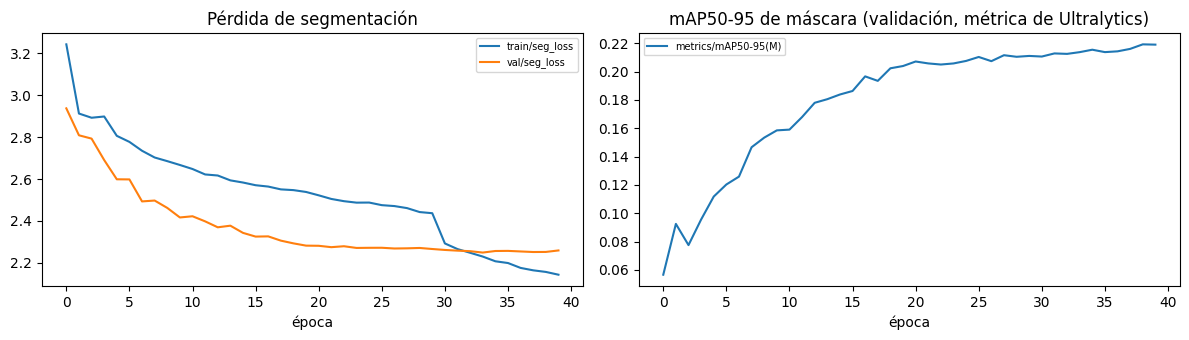

In [8]:
# Curvas de entrenamiento (si existe results.csv)
try:
    import matplotlib.pyplot as plt
    df = pd.read_csv(RUN_DIR / "results.csv"); df.columns = [c.strip() for c in df.columns]
    cm = [c for c in df.columns if "mAP50-95(M)" in c]; lc = [c for c in df.columns if "seg_loss" in c]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for c in lc: ax[0].plot(df[c], label=c)
    for c in cm: ax[1].plot(df[c], label=c)
    ax[0].set_title("Pérdida de segmentación"); ax[1].set_title("mAP50-95 de máscara (validación, métrica de Ultralytics)")
    for a in ax: a.legend(fontsize=7); a.set_xlabel("época")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

---
### ✅ End of training

This concludes the **training** phase: weights are saved in `{WORK}/runs/{RUN_NAME}/weights/best.pt` (in your Drive). If you only needed the trained model, you can stop here.

Sections 3–5 below (predictions, `pycocotools` evaluation, latency, and `resultados/B2_*.json`) are the **evaluation** consumed by notebook 99. They run afterward and can be repeated without retraining (the `DONE.json` marker prevents retraining).

## 3. Predictions and evaluation (`pycocotools`)

Predicts on **val** and **test** images (excluding flagged ones), with `conf=0.001` and masks at original resolution. Predictions are saved in COCO format (RLE) so notebook 99 can reuse them. Evaluated **class-aware** and also in **agnostic** mode from the same predictions, to compare mask quality with A2.

> **Classification.** Each detection carries its class (`category_id = idx + 1`). `evaluate_all`'s *class-aware* mode requires the class to match in addition to the mask (segmentation + classification); *agnostic* mode ignores class and measures mask quality only. On test, per-class AP is also computed (`per_class=True`).

In [9]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(str(BEST))
NAMES = model.names                                   # {idx: nombre de clase}

def _first_val_image():
    return str(YOLO_DIR / "images" / "val" / next(im for im in prep.images("val") if im["id"] not in BAD["val"])["file_name"])

def _fp16_kwargs():
    """'half' está deprecado: se prueba 'quantize' y, si esta versión no lo acepta, se vuelve a 'half'."""
    if not CUDA: return {}
    for kw in ({"quantize": "fp16"}, {"half": True}):
        try:
            model.predict(_first_val_image(), imgsz=CFG["imgsz"], device=DEVICE, verbose=False, **kw)
            return kw
        except Exception:
            continue
    return {}
FP16 = _fp16_kwargs()
print("Opción de precisión reducida:", FP16 or "ninguna (FP32)")

SCORES = {}
# --- Memoria: infiere por bloques, limita el lado mayor de la foto y vacía la caché de CUDA ---
# retina_masks=True devuelve la máscara al tamaño de la imagen de entrada. Con fotos muy grandes,
# un solo lote podía pedir decenas de GB (OOM). Aquí se limita el lado mayor y se infiere de una en una.
import gc
from PIL import Image

_pred_max = CFG.get("pred_max_side", max(1024, 2 * CFG["imgsz"]))
PRED_MAX_SIDE = int(_pred_max) if _pred_max else 0  # 0 / None = sin límite
PRED_CHUNK = int(CFG.get("pred_chunk", 16))
PRED_BATCH = int(CFG.get("pred_batch", 1))

def _load_for_pred(path, info):
    im, _, _, _ = fu.load_image_oriented(path, info)
    if PRED_MAX_SIDE and max(im.size) > PRED_MAX_SIDE:
        r = PRED_MAX_SIDE / max(im.size)
        im = im.resize((max(1, round(im.size[0] * r)), max(1, round(im.size[1] * r))), Image.BILINEAR)
    return im

def predict_dets(split, limit=None):
    infos = [im for im in prep.images(split) if im["id"] not in BAD[split]]
    if limit: infos = infos[:limit]
    paths = [YOLO_DIR / "images" / split / im["file_name"] for im in infos]

    dets, all_sc = [], []
    print(f"  [{split}] {len(infos)} imágenes | max_side={PRED_MAX_SIDE or 'sin límite'} | chunk={PRED_CHUNK} | batch={PRED_BATCH}")
    for start in range(0, len(infos), PRED_CHUNK):
        chunk = infos[start:start + PRED_CHUNK]
        imgs = [_load_for_pred(paths[start + j], info) for j, info in enumerate(chunk)]
        for info, r in zip(chunk, model.predict(imgs, imgsz=CFG["imgsz"], conf=CFG["conf"], max_det=CFG["max_det"],
                                                 device=DEVICE, retina_masks=True, stream=True, verbose=False,
                                                 batch=PRED_BATCH, **FP16)):
            if r.masks is None or len(r.masks) == 0: continue
            masks = r.masks.data.cpu().numpy() > 0.5
            scores = r.boxes.conf.cpu().numpy(); cls = r.boxes.cls.cpu().numpy().astype(int)
            for m, sc, c in zip(masks, scores, cls):
                if not m.any(): continue
                cat = 1 if CFG["agnostic"] else int(c) + 1          # category_id = class_idx + 1
                dets.append(fu.make_det(info["id"], cat, sc, mask=m, info=info))
                all_sc.append(float(sc))
        del imgs
        gc.collect()
        if CUDA: torch.cuda.empty_cache()
    SCORES[split] = all_sc
    return infos, dets


EVAL, PRED_FILES = {}, {}
for s in ("val", "test"):
    t0 = time.time()
    infos, dets = predict_dets(s, limit=50 if CFG["pilot"] else None)
    ids = [im["id"] for im in infos]
    PRED_FILES[s] = str(fu.save_predictions(dets, PRED_DIR / f"{RUN_NAME}_{s}.json"))
    if CFG["agnostic"]:
        EVAL[s] = {"agnostic": fu.evaluate_segm(prep.coco(s, agnostic=True), dets, agnostic=True, img_ids=ids, n_folds=CFG["eval_folds"])}
    else:
        # evaluate_all: modo con clases (clasificación + segmentación) y modo agnóstico, a partir de las mismas detecciones
        EVAL[s] = fu.evaluate_all(prep.coco(s), dets, img_ids=ids, per_class=(s == "test"), n_folds=CFG["eval_folds"])
    sc = SCORES[s]
    rng = f", score {min(sc):.3f}–{max(sc):.3f}" if sc else ""
    print(f"[{s}] {len(ids)} imágenes, {len(dets):,} detecciones ({len(dets)/max(len(ids),1):.1f}/img){rng}, {time.time()-t0:.0f} s")
    del dets
    gc.collect()
    if CUDA: torch.cuda.empty_cache()

import pandas as pd
rows = []
for s, d in EVAL.items():
    for k, m in d.items():
        rows.append(dict(split=s, modo=k, AP=m["AP"], AP50=m["AP50"], AP75=m["AP75"], APs=m["APs"], APm=m["APm"], APl=m["APl"],
                         AR100=m["AR100"], AP_folds=f"{m.get('AP_fold_mean', float('nan')):.3f}±{m.get('AP_fold_std', float('nan')):.3f}"))
print(pd.DataFrame(rows).round(3).to_string(index=False))
if CFG["pilot"]:
    print("\nℹ️ Modo piloto (1 época, 5 % de los datos): un AP cercano a 0 es lo esperado. Solo valida que el flujo funciona.")

Opción de precisión reducida: {'quantize': 'fp16'}
  [val] 946 imágenes | max_side=1024 | chunk=16 | batch=1
[val] 946 imágenes, 12,869 detecciones (13.6/img), score 0.001–0.973, 69 s
  [test] 3911 imágenes | max_side=1024 | chunk=16 | batch=1
[test] 3911 imágenes, 51,783 detecciones (13.2/img), score 0.001–0.987, 276 s
split        modo    AP  AP50  AP75   APs   APm   APl  AR100    AP_folds
  val class_aware 0.163 0.229 0.178 0.000 0.067 0.178  0.240 0.229±0.033
  val    agnostic 0.397 0.613 0.433 0.000 0.068 0.436  0.565 0.402±0.035
 test class_aware 0.148 0.207 0.164 0.050 0.082 0.157  0.236 0.188±0.014
 test    agnostic 0.387 0.601 0.422 0.041 0.146 0.411  0.553 0.388±0.019


In [10]:
from collections import defaultdict
from pycocotools import mask as mu

def classification_on_matches(split, dets, ids, score_thr, iou_thr=0.5):
    """Empareja cada GT con la detección de mayor IoU (≥ iou_thr, sin mirar la clase) y compara las clases."""
    g = fu._gt_dict(prep.coco(split)); idset = set(ids)
    gd = dict(images=[im for im in g["images"] if im["id"] in idset],
              annotations=[a for a in g["annotations"] if a["image_id"] in idset], categories=g["categories"])
    gtc = fu._make_coco(gd)
    cat_ids = sorted(c["id"] for c in g["categories"]); idx = {c: i for i, c in enumerate(cat_ids)}
    nm = {c["id"]: c["name"] for c in g["categories"]}; names = [nm[c] for c in cat_ids]
    gts = defaultdict(list)
    for a in gd["annotations"]:
        if not a.get("iscrowd", 0): gts[a["image_id"]].append(a)
    dts = defaultdict(list)
    for d in dets:
        if d["image_id"] in idset and d["score"] >= score_thr: dts[d["image_id"]].append(d)
    y_true, y_pred = [], []
    n_gt = sum(len(v) for v in gts.values()); n_det = sum(len(v) for v in dts.values())
    for iid, gl in gts.items():
        dl = sorted(dts.get(iid, []), key=lambda d: -d["score"])
        if not dl: continue
        iou = np.asarray(mu.iou([d["segmentation"] for d in dl], [gtc.annToRLE(a) for a in gl], [0] * len(gl)))
        used = set()
        for i, d in enumerate(dl):
            for j in np.argsort(-iou[i]):
                if iou[i, j] < iou_thr: break
                if j in used: continue
                used.add(int(j)); y_true.append(idx[gl[j]["category_id"]]); y_pred.append(idx[d["category_id"]]); break
    out = dict(score_thr=score_thr, iou_thr=iou_thr, n_gt=n_gt, n_det=n_det, n_matched=len(y_true),
               det_recall=len(y_true) / max(n_gt, 1), det_precision=len(y_true) / max(n_det, 1))
    if y_true:
        K = len(names); P = np.zeros((len(y_true), K), dtype=np.float32); P[np.arange(len(y_true)), y_pred] = 1.0
        cm = fu.classification_metrics(y_true, P, names=names, topk=(1,))
        out.update(accuracy=cm["top1"], macro_f1=cm["macro_f1"], balanced_acc=cm["balanced_acc"],
                   per_class=cm["per_class"], top_confusions=cm["top_confusions"])
    return out


# --- Clasificación sobre las instancias detectadas (solo con clases) ---
CLS = {}
if not CFG["agnostic"]:
    SCORE_THR = CFG["conf_latency"] if not CFG["pilot"] else 0.05      # umbral "de uso real"; más bajo en el piloto
    for s in ("val", "test"):
        ids_s = [im["id"] for im in prep.images(s) if im["id"] not in BAD[s]]
        if CFG["pilot"]: ids_s = ids_s[:50]
        CLS[s] = classification_on_matches(s, fu.load_predictions(PRED_FILES[s]), ids_s, SCORE_THR)
        c = CLS[s]
        print(f"[{s}] GT {c['n_gt']:,} | detecciones (score≥{SCORE_THR}) {c['n_det']:,} | emparejadas (IoU≥0.5) {c['n_matched']:,} "
              f"| recall det. {c['det_recall']:.3f} | precisión det. {c['det_precision']:.3f}")
        if "accuracy" in c:
            print(f"      exactitud de clase {c['accuracy']:.3f} | macro-F1 {c['macro_f1']:.3f} | recall balanceado {c['balanced_acc']:.3f}")
        # resumen escalar dentro de EVAL -> se guarda en resultados/B2_*.json (sin listas largas)
        EVAL[s]["matched_cls"] = {k: v for k, v in c.items() if k not in ("per_class", "top_confusions")}
        pd.DataFrame(c.get("per_class", [])).to_csv(PRED_DIR / f"{RUN_NAME}_{s}_clasif_por_clase.csv", index=False)
        (PRED_DIR / f"{RUN_NAME}_{s}_clasif.json").write_text(json.dumps(c, indent=1, default=str))
    if CFG["pilot"]:
        print("ℹ️ Piloto: estos valores solo comprueban que el cálculo funciona.")

# Copia legible de las métricas de AP (se guarda en Drive junto a las predicciones)
pd.DataFrame(rows).round(4).to_csv(PRED_DIR / f"{RUN_NAME}_metricas.csv", index=False)
(PRED_DIR / f"{RUN_NAME}_eval.json").write_text(json.dumps(EVAL, indent=1, default=str))
print("Métricas guardadas en:", PRED_DIR)

[val] GT 1,708 | detecciones (score≥0.25) 977 | emparejadas (IoU≥0.5) 780 | recall det. 0.457 | precisión det. 0.798
      exactitud de clase 0.624 | macro-F1 0.390 | recall balanceado 0.429
[test] GT 7,405 | detecciones (score≥0.25) 4,116 | emparejadas (IoU≥0.5) 3,267 | recall det. 0.441 | precisión det. 0.794
      exactitud de clase 0.674 | macro-F1 0.386 | recall balanceado 0.395
Métricas guardadas en: /content/drive/MyDrive/calorie_counter/predicciones


## 4. Efficiency and Ultralytics benchmark

Latency is **end-to-end** (read, preprocessing, inference with original-resolution masks, and postprocessing), batch = 1 and `conf=0.25`, on this session's GPU. Compare only among models measured on the **same GPU**.

In [11]:
sample = _first_val_image()
def _one():
    model.predict(sample, imgsz=CFG["imgsz"], conf=CFG["conf_latency"], max_det=CFG["max_det"], device=DEVICE,
                  retina_masks=True, verbose=False, **FP16)
fu.reset_gpu_peak()
LAT = fu.measure_latency(_one, warmup=5, iters=30)
EFF = dict(params=fu.count_params(model.model), latency=LAT, gpu_mem_mb=fu.gpu_memory_mb(), gpu=GPU, imgsz=CFG["imgsz"])
print(f"Parámetros: {EFF['params']/1e6:.1f} M | latencia: {LAT['mean_ms']:.1f} ± {LAT['std_ms']:.1f} ms (p95 {LAT['p95_ms']:.1f}) en {GPU}")

# Referencia (NO se usa para comparar): métrica interna de Ultralytics sobre el test exportado
ULTRA = {}
if not CFG["pilot"]:
    try:
        v = model.val(data=DATA_YAML, split="test", imgsz=CFG["imgsz"], batch=CFG["batch"], device=DEVICE, plots=False, verbose=False)
        ULTRA = dict(seg_map50_95=float(v.seg.map), seg_map50=float(v.seg.map50))
        print("Ultralytics (referencia):", ULTRA)
    except Exception as e:
        print("No se pudo obtener la referencia de Ultralytics:", type(e).__name__, e)

Parámetros: 3.3 M | latencia: 15.8 ± 0.2 ms (p95 16.1) en NVIDIA L4
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n-seg summary (fused): 137 layers, 2,782,029 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 969.6±264.7 MB/s, size: 37.8 KB)
val: Scanning /content/yolo_data/cls/labels/test... 3911 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3911/3911 1.1Kit/s 3.5s
val: /content/yolo_data/cls/images/test/007528.jpg: 1 duplicate labels removed
val: /content/yolo_data/cls/images/test/008173.jpg: 1 duplicate labels removed
val: /content/yolo_data/cls/images/test/008538.jpg: 2 duplicate labels removed
val: /content/yolo_data/cls/images/test/008621.jpg: corrupt JPEG restored and saved
val: /content/yolo_data/cls/images/test/008626.jpg: corrupt JPEG restored and saved
val: /content/yolo_data/cls/images/test/008629.jpg: 5 duplicate labels removed
val: /content/yolo_data/cls/images/test/008742.jpg: 1 duplic

## 5. Save results

In [12]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model=f"YOLO26{CFG['model_size']}-seg", metrics=EVAL, prep=prep, cfg=CFG, seed=CFG["seed"],
    efficiency=EFF,
    train=dict(pretrained="COCO ("+CFG["weights"]+")", epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"],
               time_s=INFO.get("time_s"), batch=CFG["batch"], imgsz=CFG["imgsz"], pilot=CFG["pilot"]),
    files=dict(weights=str(BEST), pred_val=PRED_FILES["val"], pred_test=PRED_FILES["test"], yolo_data=DATA_YAML),
    notes=("Segmentador agnostico (una clase 'food')." if CFG["agnostic"] else "Segmentador con 323 clases.") + f" Ultralytics ref: {ULTRA}",
    out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

Resultado guardado en: /content/drive/MyDrive/calorie_counter/resultados/B2_yolo26n.json


006458.jpg: sin detecciones con conf>=0.25
006505.jpg: coffee (0.60)
006535.jpg: sin detecciones con conf>=0.25
006540.jpg: coffee (0.80)
006545.jpg: chips_french_fries (0.92); rice (0.43); lemon (0.26)
006617.jpg: sin detecciones con conf>=0.25


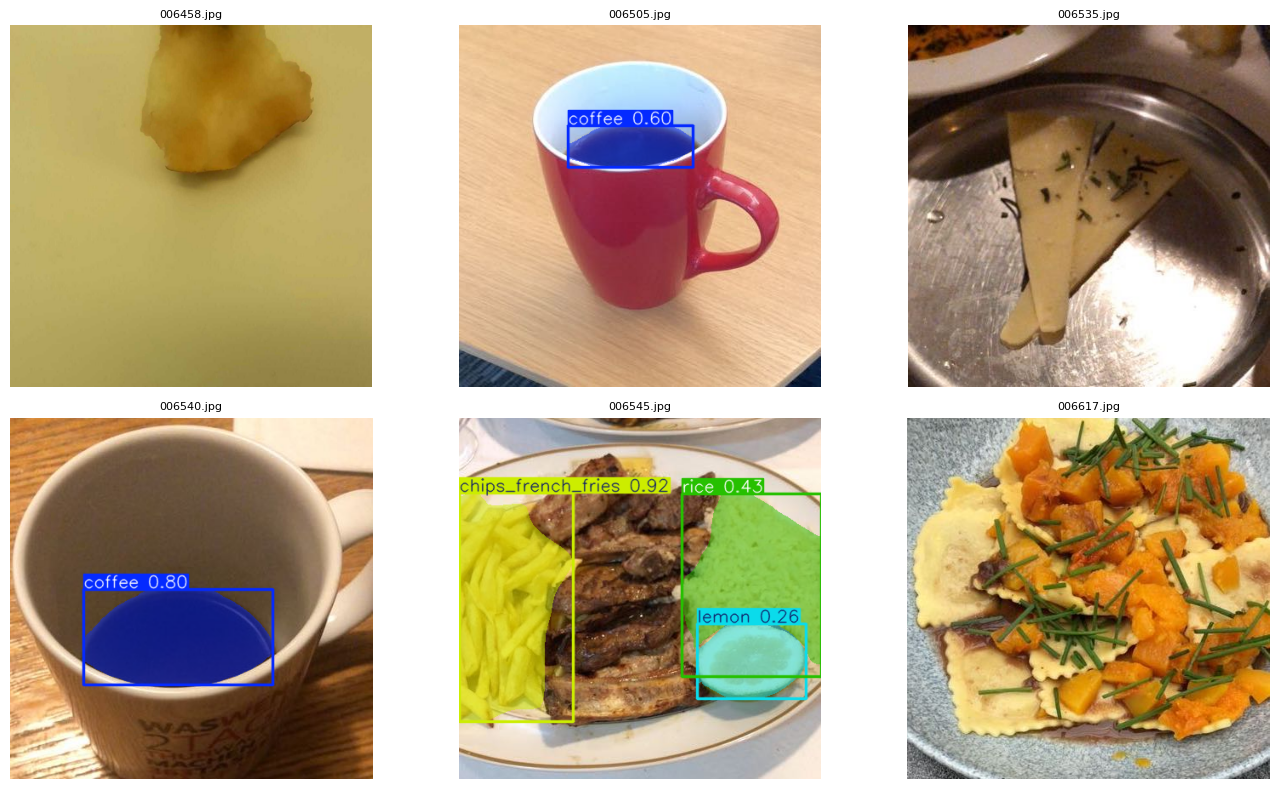

In [13]:
# Revisión cualitativa: 6 predicciones de test (máscaras + clase predicha, de Ultralytics)
try:
    import matplotlib.pyplot as plt
    tests = [im for im in prep.images("test") if im["id"] not in BAD["test"]][:6]
    viz_conf = 0.05 if CFG["pilot"] else 0.25            # el modelo del piloto apenas da scores altos
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, im in zip(axes.flat, tests):
        r = model.predict(str(YOLO_DIR / "images" / "test" / im["file_name"]), imgsz=CFG["imgsz"], conf=viz_conf,
                          device=DEVICE, retina_masks=True, verbose=False, **FP16)[0]
        ax.imshow(r.plot()[..., ::-1]); ax.axis("off"); ax.set_title(im["file_name"], fontsize=8)
        if r.boxes is not None and len(r.boxes):
            top = [f"{NAMES[int(c)]} ({float(p):.2f})" for c, p in zip(r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy())][:5]
            print(f"{im['file_name']}: " + "; ".join(top))
        else:
            print(f"{im['file_name']}: sin detecciones con conf>={viz_conf}")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Next steps
- If the pilot succeeded: set `CFG["pilot"] = False` and **Run all**. If Colab disconnects, re-run from top to bottom: data is re-extracted to local disk and training **resumes automatically** from `last.pt` in Drive.
- Compare with **A2** (same size `n`): the difference in agnostic AP measures the effect of learning classes inside the segmenter; and with **B1** (`m`) to see the effect of size.
- Results are saved in `{WORK}/resultados/B2_yolo26n*.json`; COCO predictions and metrics in `{WORK}/predicciones/`.